### Dataset
[Copernicus ERA5-Land Hourly / Daily Reanalysis Dataset](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land?tab=overview)

- **Spatial Coverage:** British Columbia Legal Boundary (`13,334` valid $0.1^\circ \times 0.1^\circ$ land grid cells clipped from `29,736` bounding-box cells; $\approx 9\text{ km} \times 11\text{ km}$ resolution)
- **Temporal Coverage:** `2018-05-01` to `2024-09-30` (`153` fire-season days/year $\times$ `7` years = `1,071` days; aggregated from 5 daily UTC timestamps `00:00, 05:00, 10:00, 15:00, 20:00 UTC`)
- **Total BC Land Rows:** `14,280,714` rows (`2,040,102` rows/year for `2018–2024`; `12,240,612` rows in `2018–2023` development set; `2,040,102` rows in `2024` holdout)

---

### 1. Coordinates & Calendar Features (6 Columns)

| Column Name | Type | Description | Range in BC Dataset |
| :--- | :--- | :--- | :--- |
| `valid_time` | `datetime64[ns]` | Daily observation date (`153` days/year for May 1 – September 30) | `2018-05-01` to `2024-09-30` |
| `latitude` | `float64` | Grid cell center latitude at $0.1^\circ$ resolution (`118` grid steps) | `48.3° N` to `60.0° N` |
| `longitude` | `float64` | Grid cell center longitude at $0.1^\circ$ resolution in `0–360°` convention | `220.9° E` to `246.0° E` |
| `longitude_deg` | `float64` | Standardized longitude in `-180–180°` convention (`((lon + 180) % 360) - 180`) | `-139.1° W` to `-114.0° W` |
| `year` | `int32` | Observation calendar year (`2018–2023` dev, `2024` holdout) | `2018` to `2024` |
| `month` | `int32` | Observation calendar month (`5` = May through `9` = September) | `5` to `9` |

---

### 2. Raw ERA5-Land Meteorology, Soil, Radiation & Land-Surface Variables (26 Data Variables)

| NetCDF Variable (`shortName`) | Source Group | Full Name & What It Measures | Physical Meaning for Wildfires | Units & Observed BC Range (`2018–2023`) |
| :--- | :--- | :--- | :--- | :--- |
| `t2m` | Surface Met (`data_1.nc`) | **2m Air Temperature:** Air temperature at 2 meters above the land surface. | Controls fuel temperature, atmospheric evaporative demand, and convective instability. | **Kelvin (K)**<br>Mean: `284.01 K` (`10.86°C`)<br>95%: `293.07 K` (`19.92°C`)<br>Max: `310.04 K` (`36.89°C`) |
| `d2m` | Surface Met (`data_1.nc`) | **2m Dewpoint Temperature:** Temperature to which air at 2m must be cooled to reach saturation. | Measures absolute atmospheric moisture; the gap between `t2m` and `d2m` drives relative humidity (`RH`) and `VPD`. | **Kelvin (K)**<br>Mean: `278.15 K` (`5.00°C`)<br>95%: `285.28 K` (`12.13°C`)<br>Max: `295.69 K` (`22.54°C`) |
| `skt` | Surface Met (`data_1.nc`) | **Skin Temperature:** Radiative temperature of the uppermost surface layer (canopy/bare soil). | Reflects direct solar heating of surface litter; strongly collinear with `t2m` ($r = 0.953$). | **Kelvin (K)**<br>Mean: `283.54 K` (`10.39°C`)<br>95%: `292.82 K` (`19.67°C`)<br>Max: `312.60 K` (`39.45°C`) |
| `u10` | Wind (`data_1.nc`) | **10m U-Component of Wind:** Eastward (zonal) wind velocity at 10m height (`+` = blowing toward East). | Captures prevailing westerly onshore flow vs. dry easterly downslope/continental winds. | **m/s**<br>Mean: `+0.51 m/s`<br>95%: `+2.15 m/s`<br>Max: `+11.95 m/s` |
| `v10` | Wind (`data_1.nc`) | **10m V-Component of Wind:** Northward (meridional) wind velocity at 10m height (`+` = blowing toward North). | Captures southerly warm advection vs. cold frontal passages that trigger sudden wind shifts. | **m/s**<br>Mean: `+0.33 m/s`<br>95%: `+1.64 m/s`<br>Max: `+13.12 m/s` |
| `sp` | Surface Met (`data_1.nc`) | **Surface Pressure:** Atmospheric pressure at the land surface. | Primarily reflects terrain elevation ($r = -0.989$ with `elevation_m`), plus synoptic high/low pressure ridges. | **Pascals (Pa)**<br>Mean: `89,114 Pa` (`891.1 hPa`)<br>95%: `97,521 Pa` |
| `tp` | Precipitation (`data_1.nc`) | **Total Precipitation:** Accumulated liquid and frozen water falling to the ground. | Directly wets surface litter and duff layers; prolonged zero-precipitation spells drive drought buildup. | **Meters (m) of water equivalent**<br>Mean: `0.00167 m` (`1.67 mm`)<br>95%: `0.00688 m` (`6.88 mm`)<br>Max: `0.0637 m` (`63.68 mm`) |
| `swvl1` | Soil Moisture (`data_0.nc`) | **Volumetric Soil Water Layer 1 (0–7 cm):** Volume of water per unit volume of top surface soil. | Direct physical proxy for fine fuel and upper duff moisture content (analogous to FFMC/DMC). | **$m^3/m^3$ (0–1 fraction)**<br>Mean: `0.33`<br>50%: `0.33`<br>95%: `0.52` |
| `swvl2` | Soil Moisture (`data_0.nc`) | **Volumetric Soil Water Layer 2 (7–28 cm):** Volumetric soil moisture in the shallow root zone. | Tracks medium-depth drying; strongly collinear with `swvl1` ($r = 0.967$) and `swvl3` ($r = 0.901$). | **$m^3/m^3$ (0–1 fraction)**<br>Mean: `0.33`<br>50%: `0.32`<br>95%: `0.52` |
| `swvl3` | Soil Moisture (`data_0.nc`) | **Volumetric Soil Water Layer 3 (28–100 cm):** Deep root-zone volumetric soil water content. | Physical proxy for seasonal deep drought and live tree water stress (analogous to Drought Code `DC`). | **$m^3/m^3$ (0–1 fraction)**<br>Mean: `0.32`<br>50%: `0.31`<br>95%: `0.52` |
| `ssrd` | Radiation (`data_1.nc`) | **Surface Solar Radiation Downwards:** Shortwave solar radiation reaching the surface (direct + diffuse). | Drives daytime fuel curing, surface heating, and cloud-free high-pressure ridge identification. | **$J/m^2$ (accumulated)**<br>Mean: `7.55e6`<br>95%: `1.18e7`<br>Max: `1.56e7` |
| `ssr` | Radiation (`data_1.nc`) | **Surface Net Solar Radiation:** Downward solar radiation minus surface albedo reflection (`(1 - albedo) * ssrd`). | Net shortwave energy absorbed by the canopy/ground; collinear with `ssrd` ($r = 0.866$). | **$J/m^2$ (accumulated)**<br>Mean: `6.20e6`<br>95%: `1.02e7`<br>Max: `1.31e7` |
| `str` | Radiation (`data_1.nc`) | **Surface Net Thermal Radiation:** Net longwave infrared radiation exchanged between surface and atmosphere. | Strongly negative under clear, dry skies (rapid radiative cooling/heating); correlates with `rh_pct` ($r = 0.835$). | **$J/m^2$ (accumulated)**<br>Mean: `-3.14e6`<br>50%: `-3.27e6` |
| `slhf` | Heat Flux (`data_1.nc`) | **Surface Latent Heat Flux:** Evaporative energy flux from the land surface to the atmosphere (negative = upward evaporation). | Measures active evapotranspiration cooling; shifts toward zero when soils dry out during flash droughts. | **$J/m^2$ (accumulated)**<br>Mean: `-2.03e6`<br>50%: `-2.10e6` |
| `pev` | Evaporation (`data_1.nc`) | **Potential Evaporation:** Atmospheric demand for evaporation assuming unlimited surface water supply. | Quantifies evaporative atmospheric thirst (negative values in ECMWF convention = upward flux). | **Meters (m) of water equivalent**<br>Mean: `-0.01 m` |
| `evabs` | Evaporation (`data_2.nc`) | **Evaporation from Bare Soil:** Direct water vapor flux from exposed mineral/organic soil. | Tracks surface soil desiccation; correlates with `slhf` ($r = 0.814$). | **Meters (m) of water equivalent**<br>Mean: `-0.0005 m` |
| `evatc` | Evaporation (`data_2.nc`) | **Evaporation from Top of Canopy:** Evaporation of rainfall intercepted on leaf/needle surfaces. | Indicates wet vs. dry forest canopy conditions following rain events. | **Meters (m) of water equivalent**<br>Mean: `-0.0003 m` |
| `evavt` | Evaporation (`data_2.nc`) | **Evaporation from Vegetation Transpiration:** Water extracted by roots and transpired through plant stomata. | Captures active live-fuel transpiration vs. drought-induced stomatal closure. | **Meters (m) of water equivalent**<br>Mean: `-0.0012 m` |
| `sde` | Snow (`data_2.nc`) | **Snow Depth:** Instantaneous depth of snowpack on the ground. | Marks snow-covered alpine/northern cells in May–June where wildfire ignition is physically blocked. | **Meters (m)**<br>Mean: `0.72 m`<br>50%: `0.00 m`<br>95%: `2.07 m` |
| `snowc` | Snow (`data_2.nc`) | **Snow Cover:** Percentage of the grid cell covered by snow (`0–100%`). | Collinear with `sde` ($r = 0.918$); `0%` across most of BC in July–August (`median = 0.0%`). | **Percentage (`0–100%`)**<br>Mean: `20.40%`<br>50%: `0.00%`<br>95%: `99.98%` |
| `lai_hv` | Vegetation (`data_1.nc`) | **Leaf Area Index, High Vegetation:** One-sided green leaf area per unit ground area for forests/trees. | Quantifies seasonal canopy density and crown fuel load across BC's coniferous forests. | **$m^2/m^2$**<br>Mean: `2.74`<br>50%: `2.65`<br>95%: `4.18`<br>Max: `5.48` |
| `lai_lv` | Vegetation (`data_1.nc`) | **Leaf Area Index, Low Vegetation:** Green leaf area index for grasses, shrubs, and tundra. | Tracks cured grass/shrub fuel load in interior valleys and plateaus. | **$m^2/m^2$**<br>Mean: `0.74`<br>50%: `0.77`<br>95%: `2.30`<br>Max: `3.98` |
| `cvh` | Static Land (`cvh.nc`) | **High Vegetation Cover:** Fraction of grid cell covered by tall forest canopy (`0–1`). | Distinguishes dense timber/boreal forest (`cvh -> 1.0`) from alpine/grassland (`cvh -> 0.0`). | **Fraction (`0–1`)**<br>Mean: `0.81`<br>50%: `0.97`<br>95%: `1.00` |
| `cvl` | Static Land (`cvl.nc`) | **Low Vegetation Cover:** Fraction of grid cell covered by grass/shrubs (`0–1`). | Inverse of `cvh` across BC land ($r = -0.929$). | **Fraction (`0–1`)**<br>Mean: `0.14`<br>50%: `0.02`<br>95%: `0.70` |
| `z` | Static Terrain (`geo.nc`) | **Surface Geopotential:** Gravitational potential energy per unit mass at the surface (`elevation_m * 9.80665`). | Encodes BC mountain topography, valley corridors, and elevation lapse rates. | **$m^2/s^2$**<br>Mean: `10,765`<br>95%: `17,519`<br>Max: `24,600` |
| `lsm` | Static Mask (`lsm.nc`) | **Land-Sea Mask:** Proportion of land (vs. ocean/inland lake) within the $0.1^\circ$ grid cell (`0–1`). | Confirms terrestrial cells (`mean = 0.96`, `median = 1.00` after BC boundary clipping). | **Fraction (`0–1`)**<br>Mean: `0.96`<br>50%: `1.00` |

---

### 3. Derived Physical & Wildfire Meteorology Features (10 Engineered Variables)

| Derived Variable | Formula / Physical Conversion | What It Measures & Wildfire Danger Thresholds |
| :--- | :--- | :--- |
| `t2m_c` | `t2m - 273.15` | **2m Air Temperature (°C):** Standard Celsius air temperature.<br>• Mean: `10.86°C` \| Median: `10.90°C` \| 95%: `19.92°C` \| Max: `36.89°C` |
| `d2m_c` | `d2m - 273.15` | **2m Dewpoint Temperature (°C):** Standard Celsius dewpoint temperature.<br>• Mean: `5.00°C` \| Median: `5.21°C` \| 95%: `12.13°C` \| Max: `22.54°C` |
| `skt_c` | `skt - 273.15` | **Skin Temperature (°C):** Standard Celsius surface skin temperature.<br>• Mean: `10.39°C` \| Median: `10.60°C` \| 95%: `19.67°C` \| Max: `39.45°C` |
| `vpd_kpa` | $e_s(T) - e_a(T_d)$ where $e(T) = 0.61078 \exp\left(\frac{17.27 T}{T + 237.3}\right)$ | **Vapor Pressure Deficit (kPa):** The #1 physical atmospheric driver of wildfire ignition and crown fire spread.<br>• **Very Moist:** `< 0.4 kPa`<br>• **Low Aridity:** `0.4 – 0.8 kPa`<br>• **Moderate Aridity:** `0.8 – 1.2 kPa`<br>• **High Fire Danger:** `1.2 – 1.8 kPa` (rapid fine-fuel drying)<br>• **Extreme Fire Danger:** `≥ 1.8 kPa` (explosive crown fire & blow-up threshold; Max: `5.36 kPa` during 2021 Heat Dome) |
| `rh_pct` | $100 \times \frac{e_a(T_d)}{e_s(T)}$ | **2m Relative Humidity (%):** Percentage saturation of air at 2m (`< 30%` = critical fire weather threshold).<br>• Mean: `68.94%` \| Median: `69.32%` \| 5%: `39.15%` \| 95%: `92.05%` |
| `wind_speed_10m` | $\sqrt{u_{10}^2 + v_{10}^2}$ | **10m Scalar Wind Speed (m/s):** Magnitude of horizontal wind vector driving rate of spread (ISI).<br>• Mean: `1.21 m/s` \| Median: `1.06 m/s` \| 95%: `2.62 m/s` \| Max: `15.58 m/s` (`56.1 km/h`) |
| `wind_dir_deg` | $(270 - \text{atan2}(v_{10}, u_{10}) \times \frac{180}{\pi}) \bmod 360$ | **10m Meteorological Wind Direction (`0–360°`):** Direction wind is blowing *from* (`180°` = South, `270°` = West).<br>• Mean: `209.35°` (SSW) \| Median: `226.37°` (SW onshore/interior flow) |
| `tp_mm` | `tp * 1000.0` | **Precipitation (mm):** Accumulated water depth in millimeters.<br>• Mean: `1.67 mm` \| Median: `0.55 mm` \| 95%: `6.88 mm` \| Max: `63.68 mm` |
| `sp_hpa` | `sp / 100.0` | **Surface Pressure (hPa):** Barometric surface pressure in hectopascals.<br>• Mean: `891.14 hPa` \| Median: `887.69 hPa` \| 95%: `975.21 hPa` |
| `elevation_m` | `z / 9.80665` | **Terrain Elevation (m above sea level):** Static topographic height converted from geopotential `z`.<br>• Mean: `1,097.74 m` \| Median: `1,118.18 m` \| 95%: `1,786.43 m` \| Max: `2,508.47 m` |

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Load the combined 2018-2024 BC ERA5 dataset (Parquet preferred for fast I/O, CSV fallback)
parquet_path = Path("../datasets/dataset_ERA5_18_24.parquet")
csv_path = Path("../datasets/dataset_ERA5_18_24.csv")

if parquet_path.exists():
    df_all = pd.read_parquet(parquet_path)
else:
    df_all = pd.read_csv(csv_path)

df_all['valid_time'] = pd.to_datetime(df_all['valid_time'])
df_all['year'] = df_all['valid_time'].dt.year
df_all['month'] = df_all['valid_time'].dt.month

# 2. Check combined dataset shape, date range, and unique BC grid cells
n_cells = df_all[['latitude', 'longitude_deg']].drop_duplicates().shape[0]
print(f"Total Rows (2018-2024): {df_all.shape[0]:,}")
print(f"Total Columns:          {df_all.shape[1]}")
print(f"Unique BC 0.1° Cells:   {n_cells:,}")
print(f"Date Range:             {df_all['valid_time'].min().date()} to {df_all['valid_time'].max().date()}")

# 3. Rows by Year
print("\nRows by Year:")
print(df_all['year'].value_counts().sort_index())

Total Rows (2018-2024): 14,280,714
Total Columns:          32
Unique BC 0.1° Cells:   13,334
Date Range:             2018-05-01 to 2024-09-30

Rows by Year:
year
2018    2040102
2019    2040102
2020    2040102
2021    2040102
2022    2040102
2023    2040102
2024    2040102
Name: count, dtype: int64


In [2]:
# 1. Count null (NaN) values per column and calculate percentage
null_counts = df_all.isnull().sum()
null_percentages = (null_counts / len(df_all)) * 100

null_summary = pd.DataFrame({
    'Null Count': null_counts,
    'Percentage (%)': null_percentages.round(4)
})

print("=== Null (Missing) Values per Column (2018-2024) ===")
display(null_summary)

=== Null (Missing) Values per Column (2018-2024) ===


,Null Count,Percentage (%)
valid_time,0,0.0000
latitude,0,0.0000
longitude,0,0.0000
longitude_deg,0,0.0000
swvl1,0,0.0000
swvl2,0,0.0000
swvl3,0,0.0000
lai_lv,0,0.0000
lai_hv,0,0.0000
sp,0,0.0000


In [3]:
# 2. Count exact zero (col == 0) values per column and calculate percentage
num_cols = [c for c in df_all.columns if c != 'valid_time']
zero_counts = (df_all[num_cols] == 0).sum()
zero_percentages = (zero_counts / len(df_all)) * 100

zero_summary = pd.DataFrame({
    'Zero Count': zero_counts,
    'Percentage (%)': zero_percentages.round(2)
})

print("=== Exact Zero (0) Values per Column (2018-2024) ===")
display(zero_summary)

=== Exact Zero (0) Values per Column (2018-2024) ===


,Zero Count,Percentage (%)
latitude,0,0.00
longitude,0,0.00
longitude_deg,0,0.00
swvl1,0,0.00
swvl2,0,0.00
swvl3,0,0.00
lai_lv,4464999,31.27
lai_hv,210987,1.48
sp,0,0.00
slhf,1,0.00


In [4]:
# Filter to 2018-2023 development set (keep 2024 holdout strictly untouched for EDA & feature selection)
df = df_all[df_all['year'] <= 2023].copy()
del df_all

print(f"Development Dataset (2018-2023) Rows: {len(df):,}")

# Compute physical unit conversions & derived wildfire meteorology variables
# 1. Temperatures: Kelvin -> Celsius
df['t2m_c'] = (df['t2m'] - 273.15).astype(np.float32)
df['d2m_c'] = (df['d2m'] - 273.15).astype(np.float32)
df['skt_c'] = (df['skt'] - 273.15).astype(np.float32)

# 2. Saturation Vapor Pressure (es), Actual Vapor Pressure (ea), VPD (kPa), and Relative Humidity (%)
es_kpa = 0.61078 * np.exp((17.27 * df['t2m_c']) / (df['t2m_c'] + 237.3))
ea_kpa = 0.61078 * np.exp((17.27 * df['d2m_c']) / (df['d2m_c'] + 237.3))
df['vpd_kpa'] = np.maximum(es_kpa - ea_kpa, 0.0).astype(np.float32)
df['rh_pct'] = np.clip((ea_kpa / np.maximum(es_kpa, 1e-6)) * 100.0, 0.0, 100.0).astype(np.float32)

# 3. 10m Wind Speed (m/s) & Meteorological Wind Direction (degrees)
df['wind_speed_10m'] = np.sqrt(df['u10']**2 + df['v10']**2).astype(np.float32)
df['wind_dir_deg'] = ((270.0 - np.degrees(np.arctan2(df['v10'], df['u10']))) % 360.0).astype(np.float32)

# 4. Precipitation (m -> mm), Surface Pressure (Pa -> hPa), and Elevation (geopotential z -> m)
df['tp_mm'] = (np.maximum(df['tp'], 0.0) * 1000.0).astype(np.float32)
df['sp_hpa'] = (df['sp'] / 100.0).astype(np.float32)
df['elevation_m'] = (df['z'] / 9.80665).astype(np.float32)

derived_cols = ['t2m_c', 'd2m_c', 'skt_c', 'vpd_kpa', 'rh_pct', 'wind_speed_10m', 'wind_dir_deg', 'tp_mm', 'sp_hpa', 'elevation_m']
print("Derived wildfire meteorology features added:", derived_cols)

Development Dataset (2018-2023) Rows: 12,240,612
Derived wildfire meteorology features added: ['t2m_c', 'd2m_c', 'skt_c', 'vpd_kpa', 'rh_pct', 'wind_speed_10m', 'wind_dir_deg', 'tp_mm', 'sp_hpa', 'elevation_m']


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_vars = [
    ('t2m_c', '2m Temperature (°C)', '#d95f02'),
    ('vpd_kpa', 'Vapor Pressure Deficit (kPa)', '#e7298a'),
    ('rh_pct', 'Relative Humidity (%)', '#1b9e77'),
    ('wind_speed_10m', '10m Wind Speed (m/s)', '#7570b3'),
    ('tp_mm', 'Precipitation (mm)', '#2b83ba'),
    ('swvl1', 'Topsoil Moisture 0–7cm (m³/m³)', '#66a61e'),
    ('swvl3', 'Deep Soil Moisture 28–100cm (m³/m³)', '#a6761d'),
    ('ssrd', 'Solar Radiation Downwards (J/m²)', '#e6ab02'),
    ('lai_hv', 'Leaf Area Index: High Veg (m²/m²)', '#1b7837'),
    ('cvh', 'High Vegetation Cover (0–1)', '#5aae61'),
    ('sde', 'Snow Depth (m)', '#4575b4'),
    ('elevation_m', 'Elevation (m)', '#666666'),
]

sample_df = df[[v[0] for v in plot_vars]].sample(n=min(150_000, len(df)), random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, (var, title, color) in enumerate(plot_vars):
    ax = axes[i]
    sns.histplot(
        sample_df[var],
        kde=True,
        bins=50,
        color=color,
        edgecolor=None,
        alpha=0.55,
        line_kws={'linewidth': 1.8, 'color': '#222222'},
        ax=ax
    )
    med_val = df[var].median()
    p95_val = df[var].quantile(0.95)
    ax.axvline(med_val, color='navy', linestyle='--', linewidth=1.4, label=f'Median: {med_val:.2f}')
    ax.axvline(p95_val, color='crimson', linestyle=':', linewidth=1.4, label=f'95th%: {p95_val:.2f}')
    ax.set_title(title, fontsize=10.5, fontweight='bold', pad=6)
    ax.set_xlabel('')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.5)

fig.suptitle('Distribution & Skewness of ERA5-Land Wildfire Meteorology Features (BC 2018–2023)', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
# plt.show()

NameError: name 'df' is not defined

=== 1. ERA5 Numeric Percentiles & Skewness (BC 2018-2023) ===
=== 3. Highly Collinear ERA5 Pairs (|Spearman r| >= 0.80) ===


,mean,std,50%,95%,max,skewness,missing_pct
t2m_c,10.84,5.50,10.88,19.91,37.09,0.05,0.0
d2m_c,4.99,4.56,5.21,12.15,22.56,-0.23,0.0
skt_c,10.37,5.75,10.58,19.64,40.05,-0.02,0.0
vpd_kpa,0.47,0.36,0.37,1.16,5.39,1.65,0.0
rh_pct,68.97,14.71,69.40,92.09,100.00,-0.18,0.0
wind_speed_10m,1.21,0.79,1.06,2.62,16.48,1.88,0.0
wind_dir_deg,208.96,80.48,226.05,324.32,360.00,-0.73,0.0
tp_mm,1.68,3.00,0.55,6.90,70.95,4.56,0.0
sp_hpa,891.00,45.75,887.57,975.24,1032.29,0.34,0.0
elevation_m,1099.01,434.80,1119.92,1789.51,2508.47,-0.16,0.0


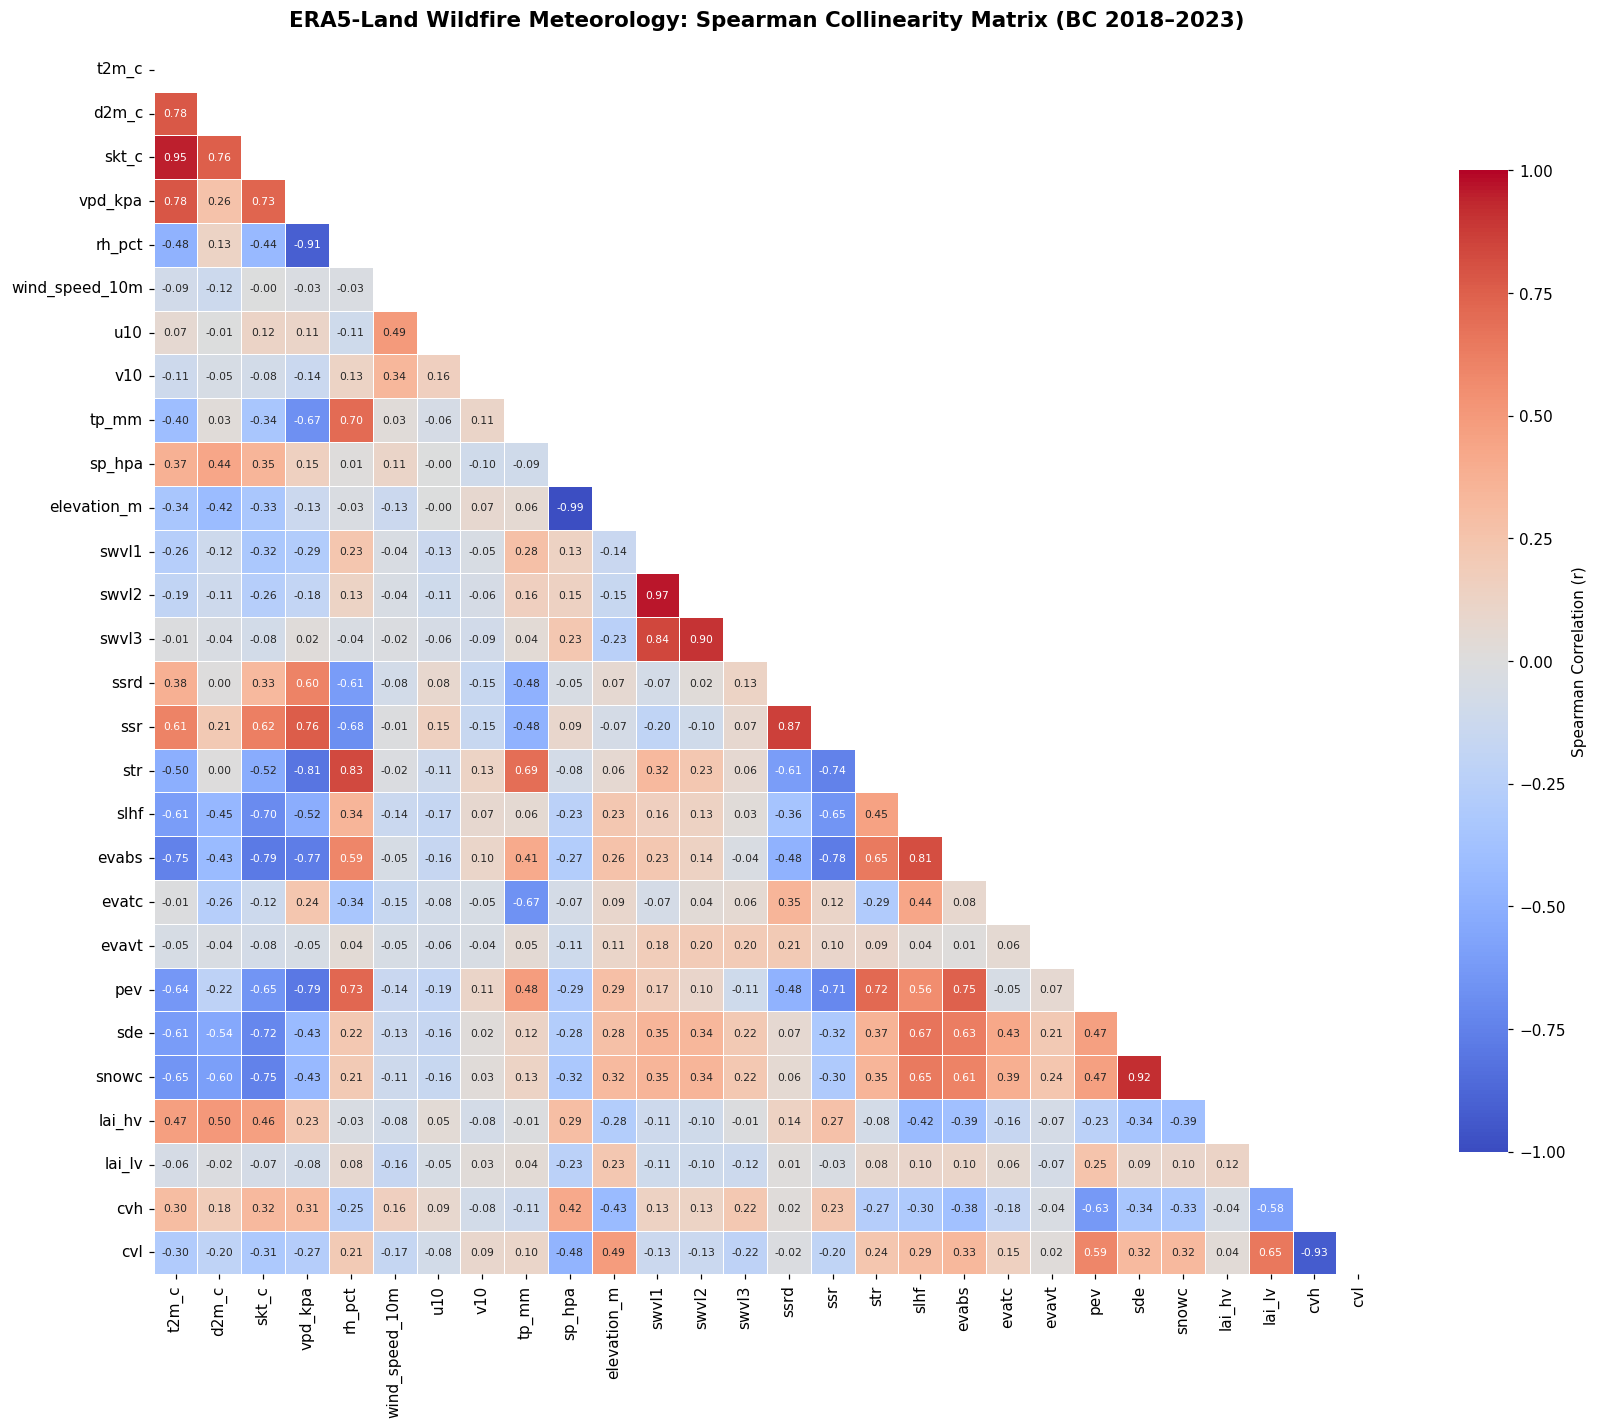

,Feature 1,Feature 2,Spearman r,|r|
0,sp_hpa,elevation_m,-0.9888,0.9888
1,swvl1,swvl2,0.9665,0.9665
2,t2m_c,skt_c,0.9531,0.9531
3,cvh,cvl,-0.9292,0.9292
4,sde,snowc,0.9178,0.9178
5,vpd_kpa,rh_pct,-0.9073,0.9073
6,swvl2,swvl3,0.9006,0.9006
7,ssrd,ssr,0.8661,0.8661
8,swvl1,swvl3,0.8414,0.8414
9,rh_pct,str,0.8347,0.8347


In [6]:
# ---------------------------------------------------------
# 1. Statistical Summary: Percentiles & Skewness
# ---------------------------------------------------------
raw_26 = [
    't2m', 'd2m', 'skt', 'u10', 'v10', 'sp', 'tp',
    'swvl1', 'swvl2', 'swvl3',
    'ssrd', 'ssr', 'str', 'slhf', 'evabs', 'evatc', 'evavt', 'pev',
    'sde', 'snowc', 'lai_hv', 'lai_lv', 'cvh', 'cvl', 'z', 'lsm'
]
all_summary_vars = derived_cols + raw_26

print("=== 1. ERA5 Numeric Percentiles & Skewness (BC 2018-2023) ===")
summary = df[all_summary_vars].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
summary['skewness'] = df[all_summary_vars].skew()
summary['missing_pct'] = (df[all_summary_vars].isnull().sum() / len(df)) * 100.0
display(summary[['mean', 'std', '50%', '95%', 'max', 'skewness', 'missing_pct']].round(2))

# ---------------------------------------------------------
# 2. Spearman Correlation & Collinearity Matrix
# ---------------------------------------------------------
corr_vars = [
    't2m_c', 'd2m_c', 'skt_c', 'vpd_kpa', 'rh_pct',
    'wind_speed_10m', 'u10', 'v10', 'tp_mm', 'sp_hpa', 'elevation_m',
    'swvl1', 'swvl2', 'swvl3',
    'ssrd', 'ssr', 'str', 'slhf', 'evabs', 'evatc', 'evavt', 'pev',
    'sde', 'snowc', 'lai_hv', 'lai_lv', 'cvh', 'cvl'
]
corr_sample = df[corr_vars].sample(n=min(300_000, len(df)), random_state=42)
corr_matrix = corr_sample.corr(method='spearman')

fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 7},
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8, 'label': 'Spearman Correlation (r)'},
    ax=ax
)
ax.set_title('ERA5-Land Wildfire Meteorology: Spearman Collinearity Matrix (BC 2018–2023)', fontsize=14, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Highlight Highly Collinear Pairs (|Spearman r| >= 0.80)
# ---------------------------------------------------------
print("=== 3. Highly Collinear ERA5 Pairs (|Spearman r| >= 0.80) ===")
high_corr = []
for i in range(len(corr_vars)):
    for j in range(i + 1, len(corr_vars)):
        val = corr_matrix.iloc[i, j]
        if abs(val) >= 0.80:
            high_corr.append({
                'Feature 1': corr_vars[i],
                'Feature 2': corr_vars[j],
                'Spearman r': round(float(val), 4),
                '|r|': round(abs(float(val)), 4)
            })
high_corr_df = pd.DataFrame(high_corr).sort_values('|r|', ascending=False).reset_index(drop=True)
display(high_corr_df)

### 4. ERA5 Feature Selection & Collinearity Audit Summary

Based on the Spearman rank correlation matrix (`|r| >= 0.80`) and wildfire physical interpretability, we resolve the 6 collinear groups into a clean, non-redundant **9-Feature Core ERA5 Shortlist**:

| Collinear Group | Redundant Pair & Spearman $r$ | Feature(s) to **KEEP** | Feature(s) to **DROP** | Physical Rationale |
| :--- | :--- | :--- | :--- | :--- |
| **1. Atmospheric Aridity** | `vpd_kpa` vs `rh_pct` ($r = -0.907$)<br>`vpd_kpa` vs `str` ($r = -0.806$) | **`vpd_kpa`** | `rh_pct`, `d2m_c`, `str`, `pev` | `VPD` non-linearly combines `t2m` and `d2m` via the Clausius–Clapeyron relation and directly governs fuel drying rate and crown fire ignition. |
| **2. Surface Temperature** | `t2m_c` vs `skt_c` ($r = +0.953$) | **`t2m_c`** | `skt_c`, `t2m`, `skt` | Standard 2m air temperature is less noisy than radiative skin temperature and pairs directly with FWI meteorology. |
| **3. Soil Moisture Profile** | `swvl1` vs `swvl2` ($r = +0.967$)<br>`swvl2` vs `swvl3` ($r = +0.901$) | **`swvl1`** (0–7 cm)<br>**`swvl3`** (28–100 cm) | `swvl2` (7–28 cm) | Keeping the top litter layer (`swvl1`, fast response) and deep root zone (`swvl3`, slow seasonal drought) captures both time scales while dropping the redundant middle layer (`swvl2`). Also enables the **`swvl1 - swvl3` flash-drought gradient**. |
| **4. Solar & Heat Fluxes** | `ssrd` vs `ssr` ($r = +0.866$)<br>`slhf` vs `evabs` ($r = +0.814$) | **`ssrd`** | `ssr`, `slhf`, `evabs`, `evatc`, `evavt` | Downward shortwave solar radiation (`ssrd`) directly measures insolation and cloud-free high-pressure ridges without surface albedo coupling. |
| **5. Vegetation & Fuel Structure** | `cvh` vs `cvl` ($r = -0.929$) | **`cvh`**, **`lai_hv`** | `cvl`, `lai_lv` | In BC, `cvh + cvl ≈ 1` on vegetated land, so `cvl` is redundant. `cvh` (static forest fraction) + `lai_hv` (dynamic seasonal leaf area) capture both spatial and seasonal canopy fuel load. |
| **6. Topography & Pressure** | `sp_hpa` vs `elevation_m` ($r = -0.989$)<br>`sde` vs `snowc` ($r = +0.918$) | **`elevation_m`** | `sp_hpa`, `sp`, `z`, `snowc`, `lsm` | Surface pressure across BC's mountains is 99% determined by barometric altitude (`elevation_m`). |

=== Monthly Medians across BC Fire Season (2018-2023) ===


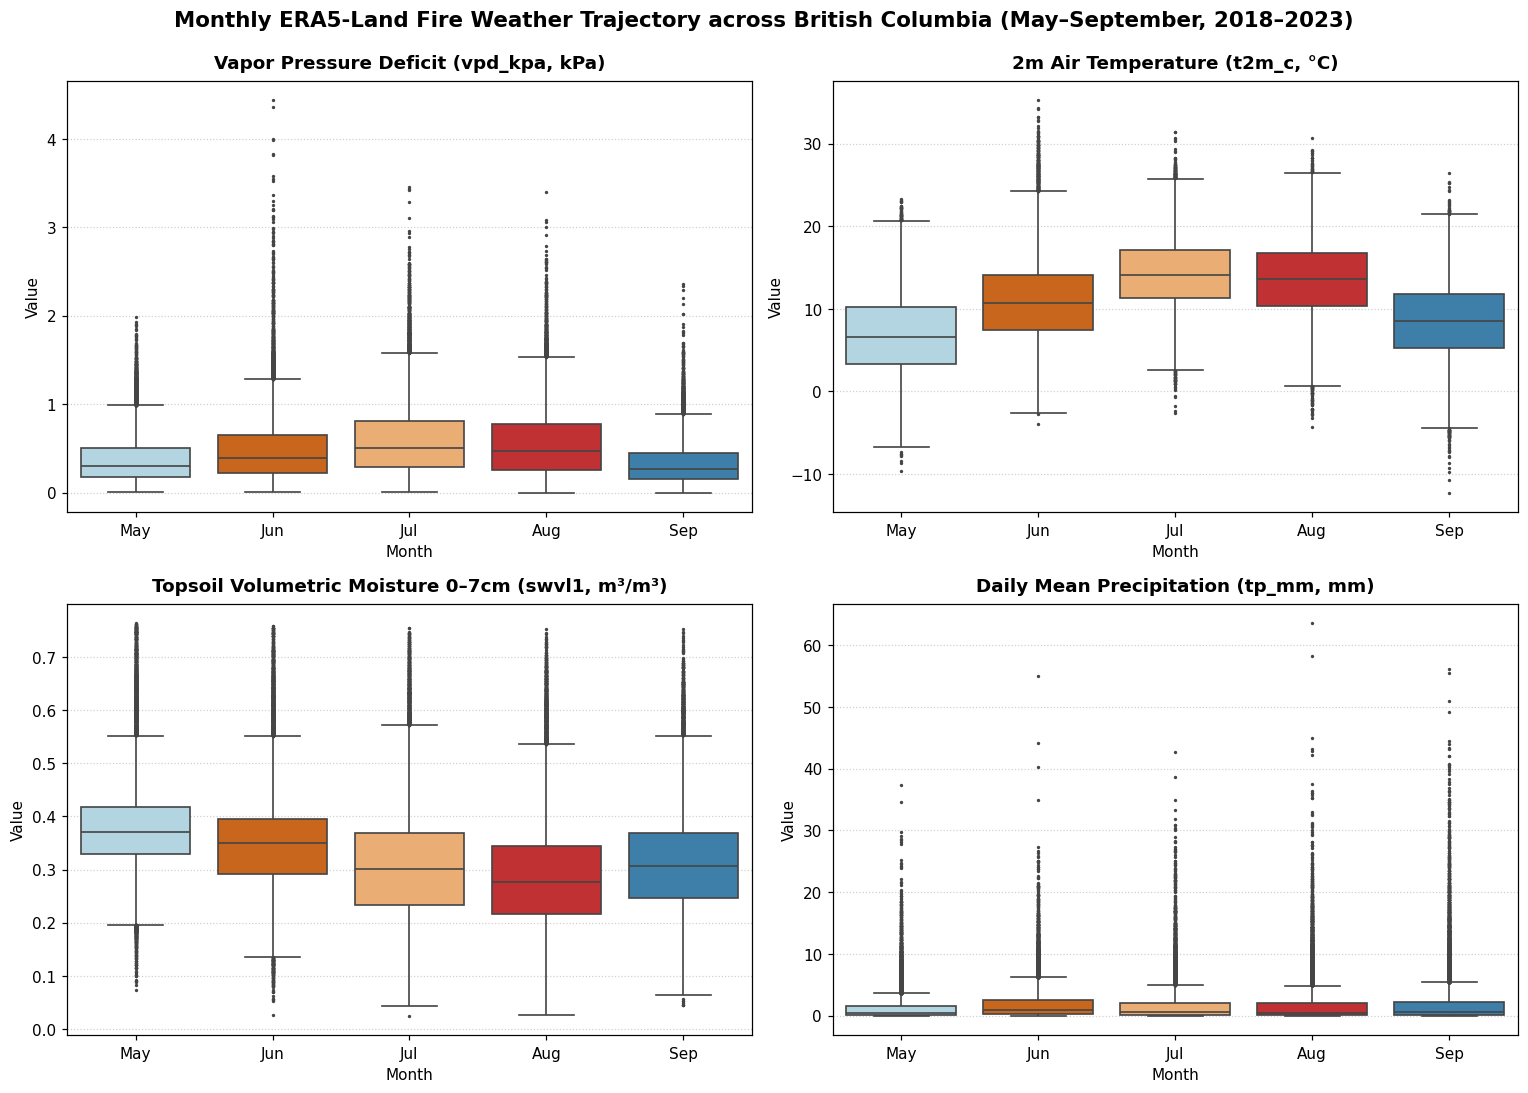

,vpd_kpa,t2m_c,rh_pct,wind_speed_10m,swvl1,swvl3,tp_mm,lai_hv
month_name,,,,,,,,
May,0.30,6.51,67.580002,1.04,0.37,0.37,0.38,2.26
Jun,0.39,10.66,68.720001,1.11,0.35,0.35,0.92,2.78
Jul,0.50,14.07,68.029999,1.03,0.30,0.30,0.58,3.12
Aug,0.47,13.55,68.790001,1.08,0.28,0.27,0.42,2.92
Sep,0.27,8.44,73.989998,1.07,0.31,0.27,0.54,2.32


In [7]:
# ---------------------------------------------------------
# 1. Monthly Seasonality Boxplots (May - September)
# ---------------------------------------------------------
month_map = {5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep'}
df['month_name'] = df['month'].map(month_map)
month_order = ['May', 'Jun', 'Jul', 'Aug', 'Sep']

selected_4 = ['vpd_kpa', 't2m_c', 'swvl1', 'tp_mm']
titles_4 = [
    'Vapor Pressure Deficit (vpd_kpa, kPa)',
    '2m Air Temperature (t2m_c, °C)',
    'Topsoil Volumetric Moisture 0–7cm (swvl1, m³/m³)',
    'Daily Mean Precipitation (tp_mm, mm)'
]

sample_box = df[['month_name', 'year'] + selected_4].sample(n=min(120_000, len(df)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
palette = ['#2b83ba', '#abd9e9', '#fdae61', '#d7191c', '#e66101']

for i, col in enumerate(selected_4):
    ax = axes[i]
    sns.boxplot(
        data=sample_box,
        x='month_name',
        y=col,
        hue='month_name',
        order=month_order,
        palette=palette,
        legend=False,
        fliersize=1.2,
        linewidth=1.1,
        ax=ax
    )
    ax.set_title(titles_4[i], fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel('Month', fontsize=10)
    ax.set_ylabel('Value', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6, axis='y')

fig.suptitle('Monthly ERA5-Land Fire Weather Trajectory across British Columbia (May–September, 2018–2023)', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. Monthly Median Progression Table
# ---------------------------------------------------------
print("=== Monthly Medians across BC Fire Season (2018-2023) ===")
monthly_medians = df.groupby('month_name')[['vpd_kpa', 't2m_c', 'rh_pct', 'wind_speed_10m', 'swvl1', 'swvl3', 'tp_mm', 'lai_hv']].median().reindex(month_order)
display(monthly_medians.round(2))

=== ERA5 VPD Atmospheric Aridity Breakdown (%) by Year (2018-2023) ===


vpd_class,Very Moist (<0.4),Low (0.4-0.8),Moderate (0.8-1.2),High (1.2-1.8),Extreme (>=1.8 kPa)
year,,,,,
2018,50.49,29.86,13.69,5.35,0.61
2019,56.48,33.90,8.02,1.49,0.11
2020,64.07,28.63,5.66,1.40,0.23
2021,55.26,27.36,9.84,5.45,2.09
2022,53.20,31.09,11.75,3.46,0.51
2023,41.11,35.87,17.27,5.28,0.47


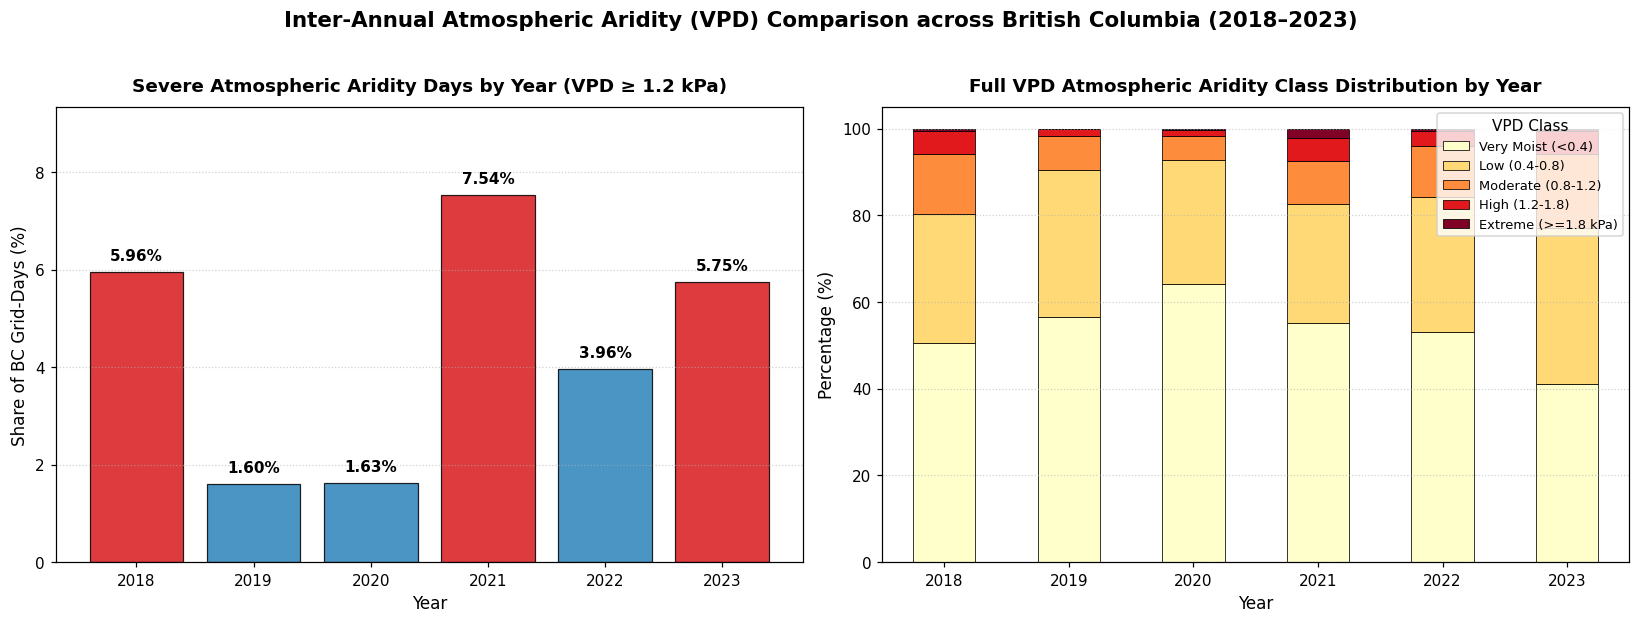

In [8]:
# ---------------------------------------------------------
# 1. Categorize VPD into Atmospheric Aridity Fire Danger Classes
# ---------------------------------------------------------
vpd_bins = [-np.inf, 0.4, 0.8, 1.2, 1.8, np.inf]
vpd_labels = ['Very Moist (<0.4)', 'Low (0.4-0.8)', 'Moderate (0.8-1.2)', 'High (1.2-1.8)', 'Extreme (>=1.8 kPa)']
df['vpd_class'] = pd.cut(df['vpd_kpa'], bins=vpd_bins, labels=vpd_labels)

annual_vpd = pd.crosstab(df['year'], df['vpd_class'], normalize='index') * 100.0
annual_high_ext = (annual_vpd['High (1.2-1.8)'] + annual_vpd['Extreme (>=1.8 kPa)']).round(2)

print("=== ERA5 VPD Atmospheric Aridity Breakdown (%) by Year (2018-2023) ===")
display(annual_vpd.round(2))

# ---------------------------------------------------------
# 2. Plot: Inter-Annual High/Extreme Aridity & Full Class Breakdown
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

colors = ['#d7191c' if yr in [2018, 2021, 2023] else '#2b83ba' for yr in annual_high_ext.index]
bars = ax1.bar(annual_high_ext.index.astype(str), annual_high_ext.values, color=colors, alpha=0.85, edgecolor='black', linewidth=0.8)

ax1.set_title('Severe Atmospheric Aridity Days by Year (VPD ≥ 1.2 kPa)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('Share of BC Grid-Days (%)', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6, axis='y')
ax1.set_ylim(0, max(annual_high_ext.values) + 1.8)

for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., h + 0.18, f'{h:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

annual_vpd[vpd_labels].plot(
    kind='bar',
    stacked=True,
    colormap='YlOrRd',
    edgecolor='black',
    linewidth=0.5,
    ax=ax2
)
ax2.set_title('Full VPD Atmospheric Aridity Class Distribution by Year', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel('Percentage (%)', fontsize=11)
ax2.tick_params(axis='x', rotation=0)
ax2.legend(title='VPD Class', fontsize=8.5, loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6, axis='y')

fig.suptitle('Inter-Annual Atmospheric Aridity (VPD) Comparison across British Columbia (2018–2023)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

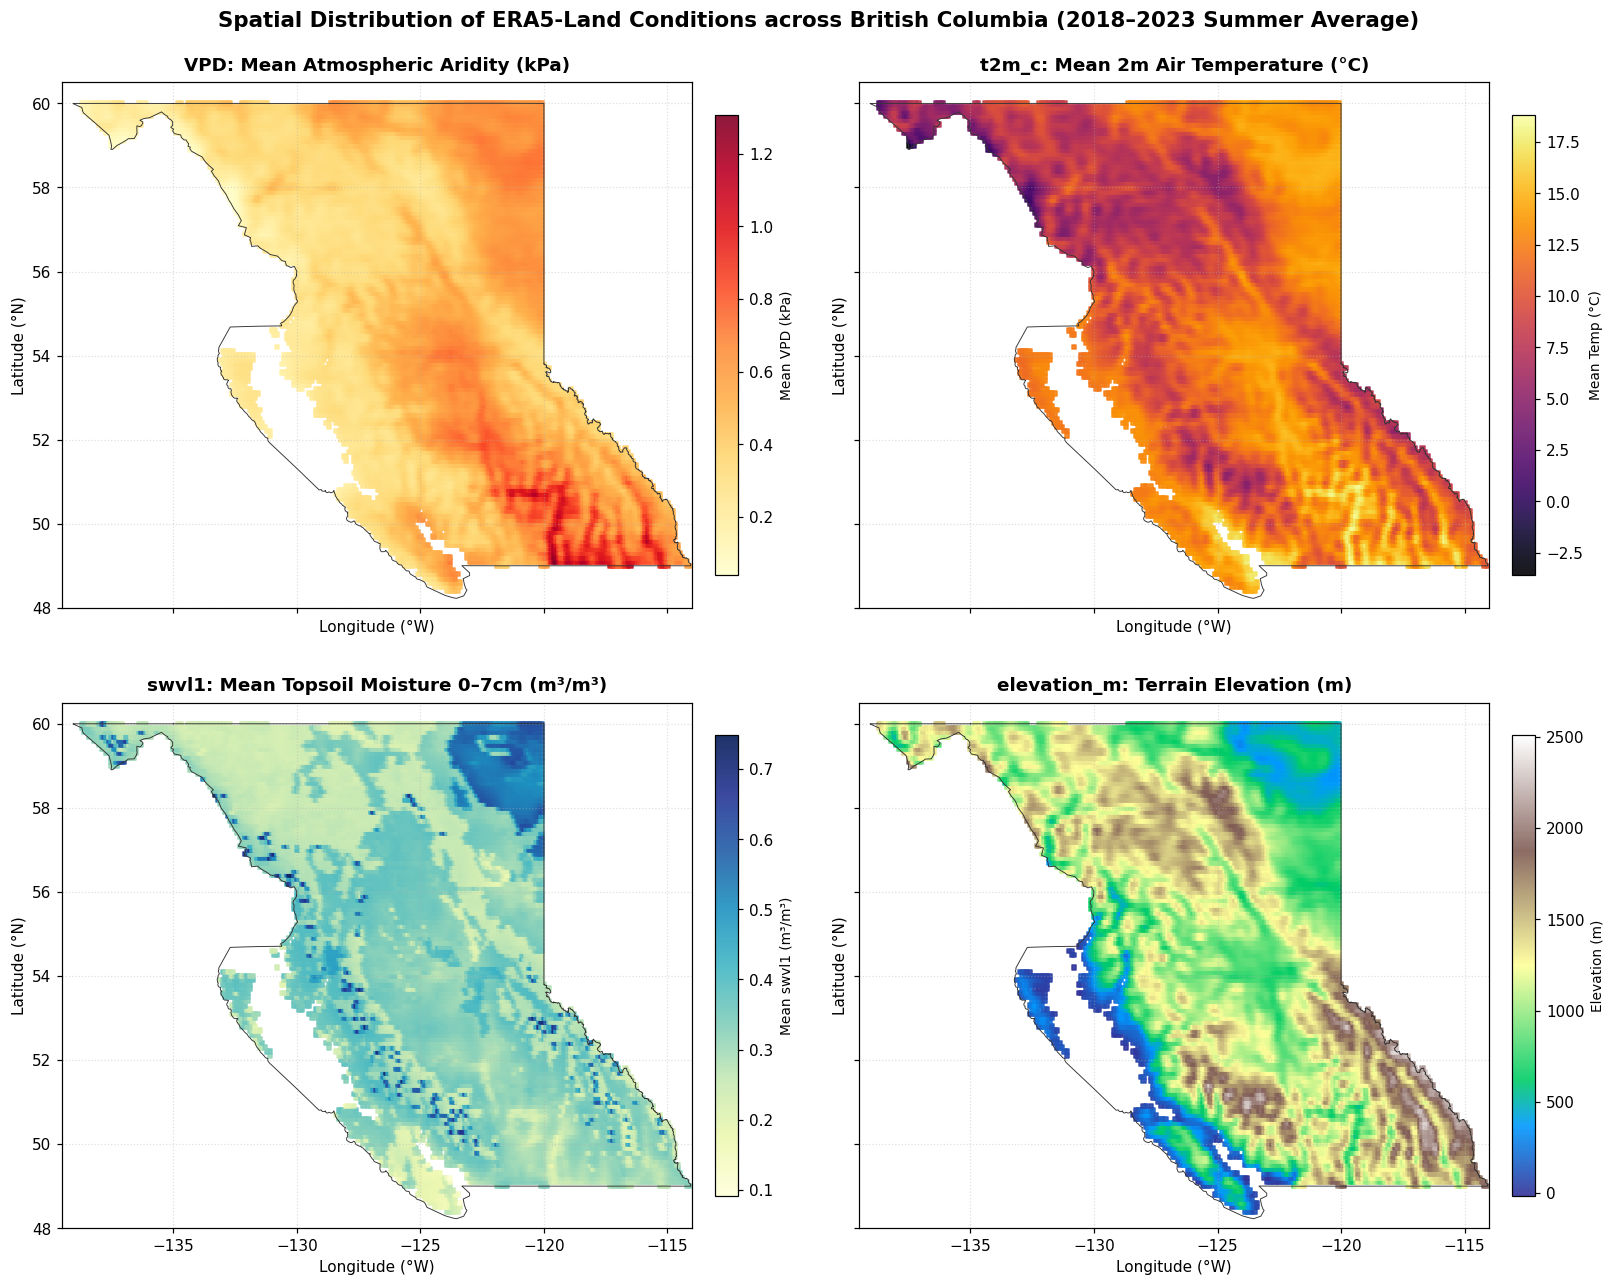

In [9]:
import json
from shapely.geometry import shape

# ---------------------------------------------------------
# 1. Load BC Legal Boundary for Map Outline
# ---------------------------------------------------------
boundary_file = Path("../datasets/bc_legal_boundary.geojson")
if not boundary_file.exists():
    boundary_file = Path("datasets/bc_legal_boundary.geojson")

bc_polygons = []
if boundary_file.exists():
    b_data = json.loads(boundary_file.read_text(encoding="utf-8"))
    for f in b_data["features"]:
        geom = shape(f["geometry"])
        if geom.geom_type == "MultiPolygon":
            bc_polygons.extend(geom.geoms)
        else:
            bc_polygons.append(geom)

# ---------------------------------------------------------
# 2. Compute Mean Summer Values for Each Unique 0.1° BC Grid Cell
# ---------------------------------------------------------
grid_means = df.groupby(['latitude', 'longitude_deg'])[['vpd_kpa', 't2m_c', 'swvl1', 'elevation_m']].mean().reset_index()

# ---------------------------------------------------------
# 3. Plot 4 Provincial Heatmaps (Aspect-Ratio Corrected)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 12), sharex=True, sharey=True)
axes = axes.flatten()

maps_config = [
    ('vpd_kpa', 'VPD: Mean Atmospheric Aridity (kPa)', 'YlOrRd', 'Mean VPD (kPa)'),
    ('t2m_c', 't2m_c: Mean 2m Air Temperature (°C)', 'inferno', 'Mean Temp (°C)'),
    ('swvl1', 'swvl1: Mean Topsoil Moisture 0–7cm (m³/m³)', 'YlGnBu', 'Mean swvl1 (m³/m³)'),
    ('elevation_m', 'elevation_m: Terrain Elevation (m)', 'terrain', 'Elevation (m)')
]

bc_aspect = 1 / np.cos(np.deg2rad(54))

for i, (col, title, cmap, label) in enumerate(maps_config):
    ax = axes[i]
    for poly in bc_polygons:
        x, y = poly.exterior.xy
        ax.plot(x, y, color='#333333', linewidth=0.6, zorder=2)

    sc = ax.scatter(
        grid_means['longitude_deg'],
        grid_means['latitude'],
        c=grid_means[col],
        cmap=cmap,
        s=8,
        marker='s',
        alpha=0.9,
        zorder=1
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel('Longitude (°W)', fontsize=10)
    ax.set_ylabel('Latitude (°N)', fontsize=10)
    ax.set_xlim(-139.5, -114.0)
    ax.set_ylim(48.0, 60.5)
    ax.set_aspect(bc_aspect)
    ax.grid(True, linestyle=':', alpha=0.4)
    cbar = plt.colorbar(sc, ax=ax, shrink=0.75, pad=0.03)
    cbar.set_label(label, fontsize=9)

fig.suptitle('Spatial Distribution of ERA5-Land Conditions across British Columbia (2018–2023 Summer Average)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()